<a href="https://colab.research.google.com/github/natgtz0/semaforo-fuzzy/blob/main/SemaforoFuzzy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 7.6 MB/s eta 0:00:00


CONTROL DE SEMAFORO POR LOGICA DIFUSA
Volumen de tráfico (0-300 vehículos/hora): 177
Lluvia (0-50 mm/hora): 3
Hora del día (HH:MM, entre 06:00 y 20:00): 7:00
--------------------------------------------------
Volumen de tráfico:  177 vehículos/hora
Lluvia:              3.0 mm/hora
Hora del día:        07:00
--------------------------------------------------
Tiempo del semáforo: 32.50 segundos


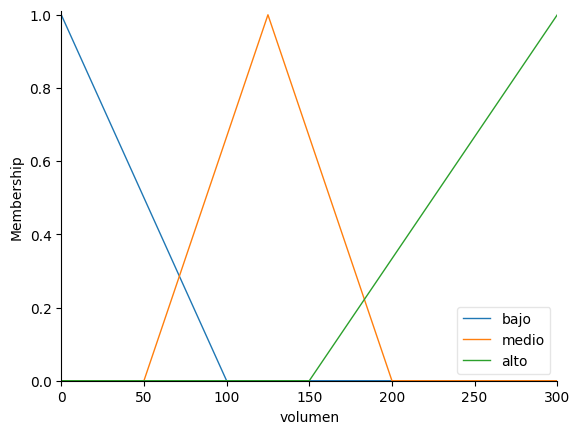

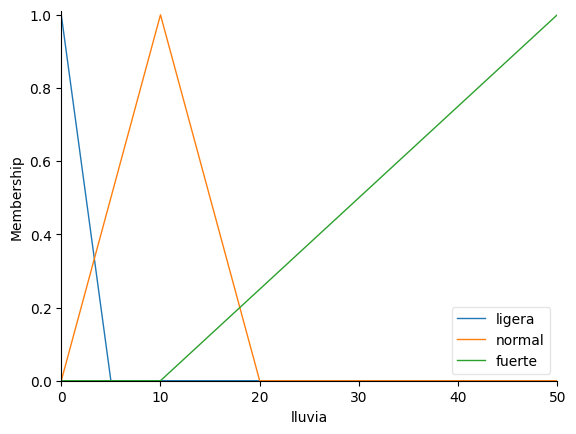

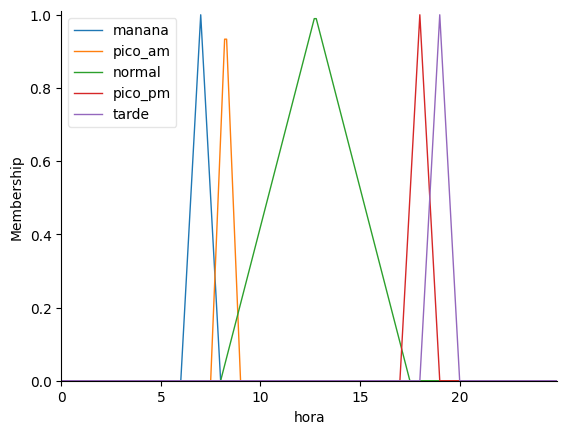

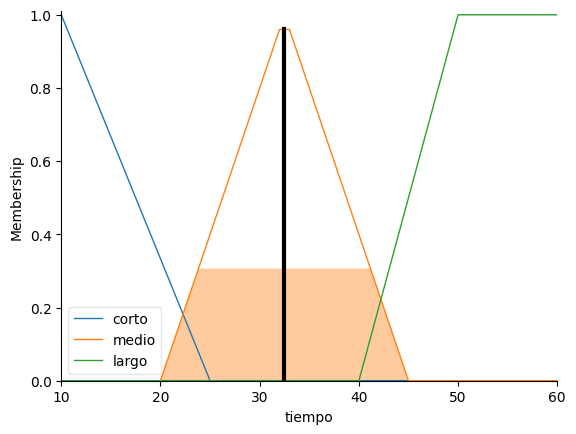

In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

volumen = ctrl.Antecedent(np.arange(0, 301, 1), 'volumen')
lluvia  = ctrl.Antecedent(np.arange(0, 51, 1),  'lluvia')
hora    = ctrl.Antecedent(np.arange(0, 25, 0.1), 'hora')
tiempo  = ctrl.Consequent(np.arange(10, 61, 1), 'tiempo')

volumen['bajo']  = fuzz.trapmf(volumen.universe, [0, 0, 0, 100])
volumen['medio'] = fuzz.trimf(volumen.universe,  [50, 125, 200])
volumen['alto']  = fuzz.trapmf(volumen.universe, [150, 300, 300, 300])

lluvia['ligera'] = fuzz.trapmf(lluvia.universe, [0, 0, 0, 5])
lluvia['normal'] = fuzz.trimf(lluvia.universe,  [0, 10, 20])
lluvia['fuerte'] = fuzz.trapmf(lluvia.universe, [10, 50, 50, 50])

hora['manana']   = fuzz.trimf(hora.universe,  [6, 7, 8])
hora['pico_am']  = fuzz.trimf(hora.universe,  [7.5, 8.25, 9])
hora['normal']   = fuzz.trimf(hora.universe, [8, 12.75, 17.5])
hora['pico_pm']  = fuzz.trimf(hora.universe,  [17, 18, 19])
hora['tarde']    = fuzz.trimf(hora.universe,  [18, 19, 20])

tiempo['corto'] = fuzz.trapmf(tiempo.universe, [10, 10, 10, 25])
tiempo['medio'] = fuzz.trimf(tiempo.universe,  [20, 32.5, 45])
tiempo['largo'] = fuzz.trapmf(tiempo.universe, [40, 50, 60, 60])

hora_pico = hora['pico_am'] | hora['pico_pm']

r1 = ctrl.Rule(volumen['alto']  & hora_pico, tiempo['largo'])
r2 = ctrl.Rule(volumen['alto']  & hora_pico & lluvia['fuerte'], tiempo['largo'])
r3 = ctrl.Rule(volumen['medio'] & hora_pico, tiempo['medio'])
r4 = ctrl.Rule(volumen['medio'] & hora_pico & lluvia['fuerte'], tiempo['largo'])
r5 = ctrl.Rule(volumen['bajo']  & hora_pico, tiempo['medio'])

r6  = ctrl.Rule(volumen['bajo']  & hora['normal'] & lluvia['ligera'], tiempo['corto'])
r7  = ctrl.Rule(volumen['bajo']  & hora['normal'], tiempo['corto'])
r8  = ctrl.Rule(volumen['medio'] & hora['normal'] & lluvia['ligera'], tiempo['medio'])
r9  = ctrl.Rule(volumen['medio'] & hora['normal'] & lluvia['normal'], tiempo['medio'])
r10 = ctrl.Rule(volumen['medio'] & hora['normal'] & lluvia['fuerte'], tiempo['largo'])
r11 = ctrl.Rule(volumen['alto']  & hora['normal'] & lluvia['ligera'], tiempo['medio'])
r12 = ctrl.Rule(volumen['alto']  & hora['normal'] & lluvia['normal'], tiempo['medio'])
r13 = ctrl.Rule(volumen['alto']  & hora['normal'] & lluvia['fuerte'], tiempo['largo'])

r14 = ctrl.Rule(volumen['bajo']  & (hora['manana'] | hora['tarde']), tiempo['corto'])
r15 = ctrl.Rule(volumen['medio'] & (hora['manana'] | hora['tarde']), tiempo['medio'])
r16 = ctrl.Rule(volumen['alto']  & (hora['manana'] | hora['tarde']), tiempo['medio'])
r17 = ctrl.Rule(volumen['alto']  & (hora['manana'] | hora['tarde']) & lluvia['fuerte'], tiempo['largo'])

sistema_control = ctrl.ControlSystem([r1, r2, r3, r4, r5,
                                       r6, r7, r8, r9, r10,
                                       r11, r12, r13, r14, r15, r16, r17])
sistema_control_difuso = ctrl.ControlSystemSimulation(sistema_control)

def leer_numero(mensaje, minimo, maximo):
    while True:
        try:
            valor = float(input(mensaje).replace(",", "."))
            if minimo <= valor <= maximo:
                return valor
            print(f"El valor debe estar entre {minimo} y {maximo}.")
        except ValueError:
            print("Ingresa un número válido.")


def leer_hora(mensaje, minimo=6.0, maximo=20.0):
    while True:
        texto = input(mensaje).strip()
        try:
            if ":" in texto:
                h, m = texto.split(":")
                valor = int(h) + int(m) / 60
            else:
                valor = float(texto.replace(",", "."))
            if minimo < valor < maximo:
                return valor
            print(f"La hora debe estar entre {minimo:g}:00 y {maximo:g}:00 "
                  "(fuera de ese rango ninguna regla se activa).")
        except ValueError:
            print("Formato no válido. Usa HH:MM (ej. 12:30) o decimal (ej. 12.5).")


print("=" * 50)
print("CONTROL DE SEMAFORO POR LOGICA DIFUSA")
print("=" * 50)

vol_usuario    = leer_numero("Volumen de tráfico (0-300 vehículos/hora): ", 0, 300)
lluvia_usuario = leer_numero("Lluvia (0-50 mm/hora): ", 0, 50)
hora_usuario   = leer_hora("Hora del día (HH:MM, entre 06:00 y 20:00): ")

sistema_control_difuso.input['volumen'] = vol_usuario
sistema_control_difuso.input['lluvia']  = lluvia_usuario
sistema_control_difuso.input['hora']    = hora_usuario

try:
    sistema_control_difuso.compute()
    valor_salida = sistema_control_difuso.output['tiempo']
except (ValueError, KeyError):
    valor_salida = None

h = int(hora_usuario)
m = round((hora_usuario - h) * 60)

print("-" * 50)
print(f"Volumen de tráfico:  {vol_usuario:.0f} vehículos/hora")
print(f"Lluvia:              {lluvia_usuario:.1f} mm/hora")
print(f"Hora del día:        {h:02d}:{m:02d}")
print("-" * 50)
if valor_salida is not None:
    print(f"Tiempo del semáforo: {valor_salida:.2f} segundos")
else:
    print("No se pudo calcular: ninguna regla se activó con esos valores.")
print("=" * 50)

volumen.view()
lluvia.view()
hora.view()
if valor_salida is not None:
    tiempo.view(sim=sistema_control_difuso)